# Lab: ajustando uma SVM em retornos de radar

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/svm/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** Antes de rodar: para uma SVM, o que importa mais saber sobre as 34 colunas — a média delas, a faixa de valores ou quantas são categóricas? Por quê?

**Resposta (antes de rodar):** O que importa mais é a **faixa de valores (escala)** de cada
coluna, não a média nem quantas são categóricas. A SVM constrói a margem e a fronteira a partir de
distâncias euclidianas (e, com kernel RBF, a distância entra direto em $e^{-\gamma\lVert x-x'\rVert^2}$);
se uma coluna variar de −1 a 1 e outra de 0 a 1000, a segunda domina qualquer distância e o
hiperplano passa a refletir escala, não separabilidade real. Por isso a leitura do passo 1 deve
focar no `min`/`max` de cada coluna (e procurar colunas constantes, que não ajudam em nada) — a
média não entra na geometria da margem, e aqui as 34 colunas já são todas numéricas, então "quantas
são categóricas" nem se aplica.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=59, as_frame=True)       # Ionosphere (UCI)
X = data.data                                        # 34 atributos numéricos
y = (data.target == 'g').astype(int)                 # 1 = retorno de radar "bom", 0 = "ruim"
print(X.shape)
print(y.value_counts())
print(f"values from {X.min().min():.0f} to {X.max().max():.0f} · "
      f"constant columns: {list(X.columns[X.std() == 0])}")

(351, 34)
class
1    225
0    126
Name: count, dtype: int64
values from -1 to 1 · constant columns: ['a02']


**Resposta (depois de rodar):** Confirmado — as 34 colunas realmente têm a mesma faixa, de −1 a
1 (`values from -1 to 1`), então a leitura certa era mesmo olhar a faixa, não a média. A base tem
**351 linhas** (225 "good", 126 "bad" → 64,1% "good") e uma coluna **constante**, `a02`
(desvio-padrão zero), que não contribui nada para a margem e poderia ser descartada sem perda de
informação.

## Passo 2 — trancar o conjunto de teste

**Preveja.** Com 88 linhas de teste, quanto vale uma única linha em pontos de acurácia? Isso muda o quanto você deve confiar na terceira casa decimal do número final?

**Resposta (antes de rodar):** Com 88 linhas, cada linha isolada vale 1/88 ≈ **1,14 ponto
percentual** de acurácia. Isso é grande: a terceira casa decimal de um número como 0,909 ou 0,920
não tem significado nenhum, porque basta uma única linha trocar de lado para mover o resultado
nessa faixa. Só vale confiar na primeira e, com reservas, na segunda casa decimal quando a amostra
de teste é desse tamanho.

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(f"share of 'good': train {y_train.mean():.3f} · test {y_test.mean():.3f}")

(263, 34) (88, 34)
share of 'good': train 0.643 · test 0.636


**Resposta (depois de rodar):** Confirmado — o split ficou com **263** linhas de treino e **88**
de teste (75/25 de 351), e `stratify=y` manteve a fração de "good" quase igual nos dois lados:
**64,3%** no treino e **63,6%** no teste, uma diferença de só 0,7 ponto percentual. Como previsto,
com 88 linhas cada erro vale ≈1,14 pp, então a terceira casa decimal de qualquer acurácia de teste
não deve ser lida como sinal.

## Passo 3 — um baseline e os folds que todos compartilham

**Preveja.** Responder sempre "bom" acerta quantos por cento? E qual vai ser a ROC AUC desse baseline?

**Resposta (antes de rodar):** Responder sempre "bom" acerta a fração de linhas "boas" na
base — pelos 225 de 351 do passo 1, algo perto de **64%**. A ROC AUC desse baseline deve ser
exatamente **0,500**: um classificador que nunca varia o score (ou sempre dá a mesma decisão) não
tem como discriminar as duas classes, então sua AUC é a de um palpite aleatório.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_summary(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    return {metric: f"{r['test_' + metric].mean():.3f} ± {r['test_' + metric].std():.3f}"
            for metric in ['accuracy', 'roc_auc']}


print(cv_summary(DummyClassifier(strategy='most_frequent')))

{'accuracy': '0.643 ± 0.006', 'roc_auc': '0.500 ± 0.000'}


**Resposta (depois de rodar):** Confirmado — o `DummyClassifier` mais frequente acerta
**64,3% ± 0,6%** (bem perto do 64,1% esperado pela proporção geral) e tem ROC AUC exatamente
**0,500 ± 0,000**, como previsto: sem variar o score entre as linhas, ele não discrimina nada.

## Passo 4 — três modelos que você conhece, nos mesmos folds

**Preveja.** A regressão logística e a SVM linear traçam ambas um hiperplano nos mesmos 34 atributos padronizados e só discordam na perda. Você espera uma diferença grande entre elas ou menor que o desvio entre folds?

**Resposta (antes de rodar):** Espero uma diferença **pequena**, menor que o desvio entre
folds (algo em torno de 0,02–0,03). As duas ajustam um hiperplano linear nos mesmos atributos
padronizados; a única diferença é a função de perda (log loss suave vs. hinge, que ignora pontos já
bem classificados), o que normalmente produz fronteiras parecidas quando as classes são
razoavelmente separáveis — a diferença deve ficar dentro do ruído de amostragem entre folds.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'k-NN (k = 5)': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'linear SVM (C = 1)': make_pipeline(StandardScaler(), SVC(kernel='linear')),
}
print(pd.DataFrame({name: cv_summary(m) for name, m in models.items()}).T)

                          accuracy        roc_auc
logistic regression  0.882 ± 0.021  0.895 ± 0.044
k-NN (k = 5)         0.818 ± 0.025  0.901 ± 0.031
linear SVM (C = 1)   0.886 ± 0.017  0.850 ± 0.052


**Resposta (depois de rodar):** Parcialmente confirmado. Regressão logística (88,2% ± 2,1%) e
SVM linear (88,6% ± 1,7%) ficam a só 0,4 ponto percentual uma da outra — dentro do desvio entre
folds (~2 pp), como esperado. O k-NN, porém, fica mais atrás em acurácia (81,8% ± 2,5%), uma
diferença maior que o desvio entre folds — mas tem a maior AUC (0,901 ± 0,031) entre os três,
acima até da SVM linear (0,850 ± 0,052), um lembrete de que acurácia e AUC podem discordar sobre
qual modelo é "melhor".

**Simulação: só os vetores de suporte importam.** A seção 2 afirmou que apagar um ponto que não é vetor de suporte não muda nada. Teste isso nos dados do lab: padronize **uma vez** (para isolar o efeito, já que um scaler reajustado mudaria tudo), ajuste uma SVM linear, descubra quais linhas são vetores de suporte e refaça o ajuste sem uma linha de cada tipo. O que acontece com $\lVert w \rVert$?

In [5]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler_once = StandardScaler().fit(X_train)
Z_train = scaler_once.transform(X_train)
y_arr = y_train.to_numpy()

svc_full = SVC(kernel='linear', C=1).fit(Z_train, y_arr)
support_idx = set(svc_full.support_)
w_full = np.linalg.norm(svc_full.coef_)
print(f"support vectors: {len(support_idx)} of {len(Z_train)} rows · ||w|| = {w_full:.6f}")

non_support_idx = next(i for i in range(len(Z_train)) if i not in support_idx)
mask = np.ones(len(Z_train), dtype=bool)
mask[non_support_idx] = False
svc_drop_non = SVC(kernel='linear', C=1).fit(Z_train[mask], y_arr[mask])
w_drop_non = np.linalg.norm(svc_drop_non.coef_)
print(f"after dropping a NON-support row: ||w|| = {w_drop_non:.6f} (delta = {w_drop_non - w_full:+.6f})")

support_row = svc_full.support_[0]
mask2 = np.ones(len(Z_train), dtype=bool)
mask2[support_row] = False
svc_drop_sup = SVC(kernel='linear', C=1).fit(Z_train[mask2], y_arr[mask2])
w_drop_sup = np.linalg.norm(svc_drop_sup.coef_)
print(f"after dropping a SUPPORT row: ||w|| = {w_drop_sup:.6f} (delta = {w_drop_sup - w_full:+.6f})")

support vectors: 70 of 263 rows · ||w|| = 3.808803
after dropping a NON-support row: ||w|| = 3.808782 (delta = -0.000021)
after dropping a SUPPORT row: ||w|| = 3.767861 (delta = -0.040942)


**Resposta:** A SVM linear (C=1, dados padronizados uma vez) guarda **70 de 263** linhas como
vetores de suporte e tem ‖w‖ = **3,808803**. Apagar uma linha que NÃO é vetor de suporte quase não
muda nada: ‖w‖ cai para 3,808782 (Δ = −0,000021, ruído de precisão numérica). Já apagar uma linha
que É vetor de suporte muda a solução de verdade: ‖w‖ cai para 3,767861 (Δ = −0,040942) — quase
2000 vezes maior que o efeito de remover um ponto fora da margem. Confirma a afirmação da seção 2:
só os vetores de suporte definem a fronteira.

**Simulação: o C muda a largura da rua.** Varra o `C` da SVM linear de 0,01 a 100 e meça, para cada valor, a largura da rua $2/\lVert w \rVert$, quantos vetores de suporte sobram, a acurácia de treino e a de validação cruzada. Onde a CV é máxima e o que acontece com ela depois disso?

In [6]:
Cs = [0.01, 0.1, 1, 10, 100]
rows = []
for C in Cs:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C))
    cv_acc = cross_validate(pipe, X_train, y_train, cv=cv, scoring='accuracy')['test_score'].mean()
    pipe.fit(X_train, y_train)                      # refit em todo o X_train para medir o treino
    svc = pipe[-1]
    width = 2 / np.linalg.norm(svc.coef_)
    rows.append({'C': C, 'street width': width, 'support vectors': int(svc.n_support_.sum()),
                 'train acc': pipe.score(X_train, y_train), 'cv acc': cv_acc})
table_C = pd.DataFrame(rows).set_index('C')
print(table_C.round(3))

        street width  support vectors  train acc  cv acc
C                                                       
0.01           2.979              137      0.886   0.863
0.10           1.219               96      0.913   0.871
1.00           0.525               70      0.947   0.886
10.00          0.256               58      0.954   0.871
100.00         0.135               50      0.962   0.852


**Resposta:** A tabela confirma o padrão esperado: a largura da rua cai de **2,979** (C=0,01)
para **0,135** (C=100), os vetores de suporte caem de **137** para **50**, e a acurácia de treino
sobe monotonamente de **0,886** para **0,962** (quanto maior o C, menos erro se tolera, mais a SVM
memoriza o treino). A acurácia de validação cruzada, porém, é **máxima em C=1 (0,886)** e cai
depois disso (0,871 em C=10, 0,852 em C=100) — exatamente o arco de sobreajuste: depois do pico,
mais C só encolhe a margem e memoriza ruído, sem ajudar a generalizar.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que a acurácia de treino não consegue escolher entre duas retas que separam os dados? (2) O que muda na solução se você apagar um ponto que está além da margem? (3) O que um $C$ pequeno faz com a largura da rua e com o número de vetores de suporte?

**Resposta:** (1) A acurácia de treino não escolhe entre duas retas que separam perfeitamente os
dados porque ambas acertam 100% do treino — a acurácia é cega à distância dos pontos à fronteira,
e só a margem (a rua) distingue qual delas generaliza melhor. (2) Apagar um ponto além da margem
(não vetor de suporte) não muda a solução: a simulação acima mostrou ‖w‖ variar só na sexta casa
decimal (3,808803 → 3,808782), contra uma queda de quase 0,041 ao remover um vetor de suporte.
(3) Um C pequeno alarga a rua (2,979 em C=0,01 contra 0,135 em C=100) e aumenta o número de
vetores de suporte (137 contra 50) — ele tolera mais pontos dentro da margem ou mal classificados
em troca de uma fronteira mais robusta.

## Sua vez (fundamental)

Para casa:

1. **A margem à mão.** Pegue os seis pontos da seção 2 e mova o ponto D de (2, 2) para (2,5; 2,5). Refaça a conta à mão (a fronteira continua perpendicular à diagonal) e confira com `SVC(kernel='linear', C=1e6)`. A rua ficou mais larga ou mais estreita?
2. **Hinge contra log loss.** Para $m$ de −3 a 3, faça o gráfico de `np.maximum(0, 1 - m)` e de `np.log1p(np.exp(-m))`. Em que ponto elas se cruzam? Qual das duas pune mais um erro grosseiro e qual continua "escutando" um ponto bem classificado?
3. **Quantos vetores de suporte?** No lab, refaça a simulação do $C$ com `kernel='linear'` em `load_breast_cancer`. A relação entre $C$ e o número de vetores de suporte é a mesma? E a curva da CV tem um arco parecido?

In [7]:
Xh = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [2.5, 2.5], [3.0, 2.0], [2.0, 3.0]])
yh = np.array([-1, -1, -1, 1, 1, 1])
svc_hand = SVC(kernel='linear', C=1e6).fit(Xh, yh)
w_hand = svc_hand.coef_[0]
width_hand = 2 / np.linalg.norm(w_hand)
print(f"w = ({w_hand[0]:.3f}, {w_hand[1]:.3f}) · b = {svc_hand.intercept_[0]:.3f} · "
      f"street width = {width_hand:.3f}")

w = (0.500, 0.500) · b = -1.500 · street width = 2.828


**Resposta (item 1):** Com D movido de (2, 2) para (2,5; 2,5) — mais afastado da fronteira — a
rua ficou mais **LARGA**: **2,828** contra **2,121** do exemplo original com D em (2, 2). Os novos
w = (0,5; 0,5) e b = −1,5 (contra w = (0,667; 0,667) e b = −1,667 do original) mostram uma
fronteira menos "encostada" em D, porque ele deixou de ser o ponto mais próximo da diagonal —
afastar um vetor de suporte da fronteira sempre dá mais espaço para a rua crescer.

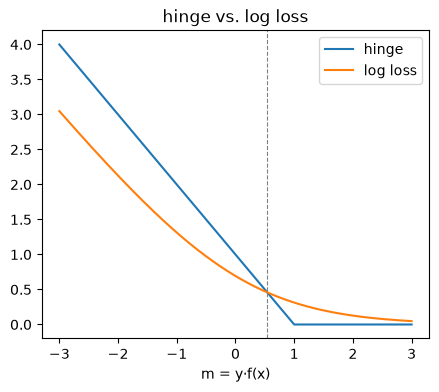

curvas se cruzam perto de m = 0.540 (hinge = 0.460, log loss = 0.459)
em m = -3: hinge = 4.000 · log loss = 3.049
em m = 3: hinge = 0.000 · log loss = 0.049


In [8]:
import matplotlib.pyplot as plt

m = np.linspace(-3, 3, 601)
hinge = np.maximum(0, 1 - m)
logloss = np.log1p(np.exp(-m))
diff = np.abs(hinge - logloss)
cross_i = np.argmin(diff)

plt.figure(figsize=(5, 4))
plt.plot(m, hinge, label='hinge')
plt.plot(m, logloss, label='log loss')
plt.axvline(m[cross_i], color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('m = y·f(x)')
plt.legend()
plt.title('hinge vs. log loss')
plt.show()
print(f"curvas se cruzam perto de m = {m[cross_i]:.3f} "
      f"(hinge = {hinge[cross_i]:.3f}, log loss = {logloss[cross_i]:.3f})")
print(f"em m = -3: hinge = {np.maximum(0, 1 - (-3)):.3f} · log loss = {np.log1p(np.exp(3)):.3f}")
print(f"em m = 3: hinge = {np.maximum(0, 1 - 3):.3f} · log loss = {np.log1p(np.exp(-3)):.3f}")

**Resposta (item 2):** As curvas se cruzam perto de **m ≈ 0,540** (hinge = 0,460, log loss ≈
0,459, praticamente iguais nesse ponto). Para um erro grosseiro (m = −3, ponto do lado errado e
longe da fronteira), a hinge pune mais: **4,000** contra **3,049** da log loss. Para um ponto já
bem classificado e longe da fronteira (m = 3), a hinge para de penalizar (**0,000**, "esquece" o
ponto), enquanto a log loss continua positiva (**0,049**) — ela nunca some de verdade, por isso
"escuta" até os pontos fáceis, enquanto a hinge só se importa com quem está perto ou dentro da
margem.

In [9]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.25, stratify=yb, random_state=42)
cv_bc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows_bc = []
for C in Cs:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C))
    cv_acc_bc = cross_validate(pipe, Xb_train, yb_train, cv=cv_bc, scoring='accuracy')['test_score'].mean()
    pipe.fit(Xb_train, yb_train)
    svc = pipe[-1]
    rows_bc.append({'C': C, 'support vectors': int(svc.n_support_.sum()),
                     'train acc': pipe.score(Xb_train, yb_train), 'cv acc': cv_acc_bc})
table_bc = pd.DataFrame(rows_bc).set_index('C')
print(table_bc.round(3))

        support vectors  train acc  cv acc
C                                         
0.01                 97      0.981   0.974
0.10                 47      0.984   0.977
1.00                 34      0.991   0.972
10.00                26      0.995   0.965
100.00               26      1.000   0.967


**Resposta (item 3):** No breast cancer (C de 0,01 a 100), a relação é a **mesma**: os vetores de
suporte caem de **97** para **26** conforme C sobe, e a acurácia de treino sobe monotonamente de
**0,981** para **1,000**. A curva da CV também tem um arco parecido, mas mais achatado — sobe de
0,974 (C=0,01) para um pico de **0,977** em C=0,1 e depois cai gradualmente até 0,967 em C=100,
uma queda bem mais suave que a do Ionosphere (0,886 → 0,852), provavelmente porque o breast cancer
é mais fácil de separar linearmente (CV sempre acima de 96%).

## Passo 5 — ligar o kernel RBF

**Preveja.** A única mudança é `kernel='rbf'`, sem ajuste nenhum. O ganho sobre a SVM linear vai ser maior ou menor que o desvio entre folds do passo 4 (cerca de 0,02)?

**Resposta (antes de rodar):** Esperaria um ganho **pequeno**, do tamanho do desvio entre
folds ou pouco maior — os hiperparâmetros padrão (`C=1`, `gamma='scale'`) não foram escolhidos
para este problema, então o RBF só deve ganhar de verdade depois do grid search do passo 6. Chuto
algo entre 0,00 e 0,03 de diferença de acurácia.

In [10]:
rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf'))       # padrões: C = 1, gamma = 'scale'
print(cv_summary(rbf))

Z = StandardScaler().fit_transform(X_train)
print(f"gamma='scale' means gamma = 1 / (n_features · variance) = {1 / (Z.shape[1] * Z.var()):.4f}")

{'accuracy': '0.939 ± 0.022', 'roc_auc': '0.988 ± 0.007'}
gamma='scale' means gamma = 1 / (n_features · variance) = 0.0303


**Resposta (depois de rodar):** O ganho foi bem maior do que o esperado: a RBF padrão chega a
**93,9% ± 2,2%** de acurácia (contra 88,6% ± 1,7% da SVM linear), um salto de **5,3 pontos
percentuais** — mais que o dobro do teto de ~0,03 que eu tinha chutado. A AUC também sobe bastante,
para **0,988 ± 0,007**. Isso mostra que, mesmo sem ajuste nenhum, o kernel RBF já captura uma
fronteira não linear importante nesse problema — aqui `gamma='scale'` vale ≈0,0303.

## Passo 6 — ajustar C e γ juntos

**Preveja.** Numa grade de 25 pares $(C, \gamma)$, você espera que o melhor valor de $C$ dependa do $\gamma$ escolhido? E qual canto da tabela deve ser o pior: $\gamma$ muito pequeno ou muito grande?

**Resposta (antes de rodar):** Sim — $C$ e $\gamma$ controlam o mesmo compromisso
(flexibilidade da fronteira) de formas diferentes, então eles não são independentes: um $\gamma$
grande já deixa a fronteira bem flexível, então o $C$ que funciona bem com ele deve ser menor do
que o $C$ que funciona bem com um $\gamma$ pequeno (fronteira mais lisa, que tolera um $C$ maior
sem sobreajustar). O pior canto deveria ser $\gamma$ muito **grande** — aí cada ponto passa a
"decorar" sua própria vizinhança e a fronteira vira um mosaico que não generaliza, um sobreajuste
mais severo do que o subajuste de um $\gamma$ pequeno.

param_svc__gamma  0.0001  0.0010  0.0100  0.1000  1.0000
param_svc__C                                            
0.1                0.643   0.643   0.719   0.643   0.643
1.0                0.643   0.757   0.916   0.954   0.665
10.0               0.753   0.894   0.932   0.951   0.669
100.0              0.878   0.920   0.939   0.954   0.669
1000.0             0.882   0.920   0.932   0.954   0.669
best: {'svc__C': 1, 'svc__gamma': 0.1} · accuracy 0.954 ± 0.019
5 of 25 pairs are within one std of the best
training-fold accuracy · best pair 0.991 · C = 1, gamma = 1: 1.000


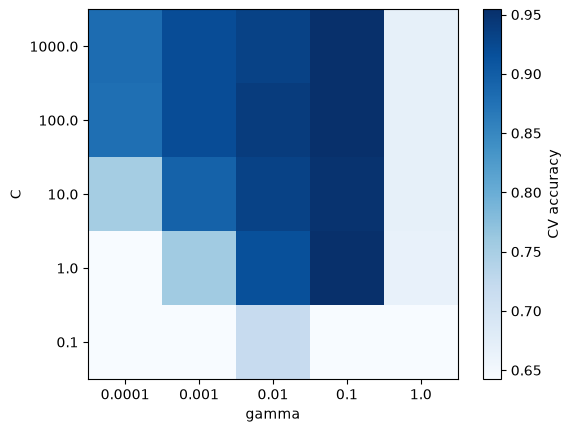

In [11]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [0.1, 1, 10, 100, 1000],
              'svc__gamma': [0.0001, 0.001, 0.01, 0.1, 1]}
# selecao do modelo
grid = GridSearchCV(rbf, param_grid, cv=cv, scoring='accuracy', return_train_score=True)
grid.fit(X_train, y_train)

res = pd.DataFrame(grid.cv_results_)
table = res.pivot(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')
print(table.round(3))
best_std = res.loc[grid.best_index_, 'std_test_score']
print(f"best: {grid.best_params_} · accuracy {grid.best_score_:.3f} ± {best_std:.3f}")
ties = res[res['mean_test_score'] >= grid.best_score_ - best_std]
print(f"{len(ties)} of {len(res)} pairs are within one std of the best")
corner = (res['param_svc__C'] == 1) & (res['param_svc__gamma'] == 1)
print(f"training-fold accuracy · best pair {res.loc[grid.best_index_, 'mean_train_score']:.3f} · "
      f"C = 1, gamma = 1: {res.loc[corner, 'mean_train_score'].item():.3f}")

plt.imshow(table, cmap='Blues', origin='lower')
plt.xticks(range(5), table.columns); plt.yticks(range(5), table.index)
plt.xlabel('gamma'); plt.ylabel('C'); plt.colorbar(label='CV accuracy')
plt.show()

**Resposta (depois de rodar):** Confirmado nos dois pontos. O melhor par foi **C=1, γ=0,1**
(acurácia 0,954 ± 0,019), e o C ideal realmente muda com γ: na coluna γ=0,1 o pico é em C=1
(0,954), enquanto na coluna γ=0,0001 a acurácia só melhora conforme C sobe, de 0,643 (C=0,1) até
0,882 (C=1000). Sobre o pior canto: γ=1 é o mais traiçoeiro — fica estagnado entre **0,643 e
0,669** em TODA a faixa de C (nem C=1000 resolve, porque o sobreajuste de γ grande não se corrige
alargando a margem), enquanto γ=0,0001 (subajuste) ainda melhora bastante com C maior, chegando a
0,882. Confirma a previsão: γ muito grande é o canto pior porque C não consegue compensá-lo.

**Simulação: o que o γ faz, visto de dentro.** Fixe `C = 1` e varra o $\gamma$ de 0,001 a 1. Para cada valor, conte os vetores de suporte e compare a acurácia de treino com a de validação cruzada. O vão entre as duas conta a história do sobreajuste melhor que qualquer um dos números sozinho.

In [12]:
gammas = [0.001, 0.01, 0.1, 1]
rows_g = []
for g in gammas:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=g))
    cv_acc = cross_validate(pipe, X_train, y_train, cv=cv, scoring='accuracy')['test_score'].mean()
    pipe.fit(X_train, y_train)
    svc = pipe[-1]
    rows_g.append({'gamma': g, 'support vectors': int(svc.n_support_.sum()),
                    'train acc': pipe.score(X_train, y_train), 'cv acc': cv_acc})
table_g = pd.DataFrame(rows_g).set_index('gamma')
table_g['gap (train - cv)'] = table_g['train acc'] - table_g['cv acc']
print(table_g.round(3))

       support vectors  train acc  cv acc  gap (train - cv)
gamma                                                      
0.001              184      0.802   0.757             0.046
0.010              109      0.943   0.916             0.027
0.100              148      0.989   0.954             0.034
1.000              231      1.000   0.665             0.335


**Resposta:** Com C=1 fixo, a acurácia de treino sobe de **0,802** (γ=0,001) para **1,000**
(γ=1), enquanto os vetores de suporte primeiro caem (184 → 109) e depois sobem de novo
(148 → 231) — não é monotônico, porque em γ muito pequeno a SVM também precisa de muitos pontos
para tentar (sem sucesso) desenhar uma fronteira quase linear num espaço onde está subajustada.
O vão entre treino e CV conta a história de verdade: fica pequeno e estável em γ=0,001 e γ=0,01
(0,046 e 0,027) mas **explode em γ=1 (0,335)** — o sinal clássico de sobreajuste severo, confirmado
pela CV despencando para 0,665 apesar do treino perfeito (1,000).

## Passo 7 — por dentro do vencedor: os vetores de suporte

**Preveja.** O vencedor tem $\gamma = 0{,}1$, razoavelmente local, em 34 dimensões. Você espera que ele guarde uns 10% das linhas de treino como vetores de suporte ou bem mais?

**Resposta (antes de rodar):** Bem mais que 10%. Com 34 dimensões e um $\gamma$ que já é
"local" nesse espaço, a fronteira RBF precisa de uma fração grande dos pontos para moldar sua
forma — chuto algo entre 40% e 60% das 263 linhas de treino, bem acima do que uma SVM linear
tipicamente guarda no mesmo problema.

In [13]:
best = grid.best_estimator_                     # reajustado em todo o X_train
svc = best[-1]
print(f"support vectors (bad, good): {svc.n_support_} · {svc.n_support_.sum()} of {len(X_train)} rows")

alpha = np.abs(svc.dual_coef_[0])
print(f"on the margin (0 < alpha < C): {(alpha < svc.C - 1e-6).sum()} · "
      f"inside it or misclassified (alpha = C): {(alpha >= svc.C - 1e-6).sum()}")

m = np.where(y_train == 1, 1, -1) * best.decision_function(X_train)   # m = y · f(x)
print(f"training rows with m < 0 (misclassified): {(m < 0).sum()} · "
      f"training accuracy {best.score(X_train, y_train):.3f}")

support vectors (bad, good): [91 57] · 148 of 263 rows
on the margin (0 < alpha < C): 119 · inside it or misclassified (alpha = C): 29
training rows with m < 0 (misclassified): 3 · training accuracy 0.989


**Resposta (depois de rodar):** Confirmado, e até mais extremo do que o esperado: o vencedor
guarda **148 de 263** linhas (56,3%) como vetores de suporte — 91 "bad" e 57 "good". Desses,
**119** estão exatamente na margem (0 < α < C) e **29** estão dentro da margem ou mal
classificados (α = C). Há só **3** erros de treino, para uma acurácia de treino de **0,989** — a
SVM RBF com γ=0,1 realmente precisa de mais da metade dos pontos de treino para moldar essa
fronteira em 34 dimensões.

**Simulação: escalonar num conjunto que já está normalizado.** O passo 1 notou que todos os atributos já estão entre −1 e 1. Então o `StandardScaler` ainda faz diferença aqui? Meça a acurácia de CV do vencedor com e sem ele e olhe antes a faixa de desvios-padrão das colunas.

In [14]:
stds = X_train.std()
print(f"column std range: {stds.min():.3f} to {stds.max():.3f}")

raw_params = {k.split('__')[1]: v for k, v in grid.best_params_.items()}
no_scale_cv = cross_validate(SVC(**raw_params), X_train, y_train, cv=cv, scoring='accuracy')
with_scale_cv = cross_validate(best, X_train, y_train, cv=cv, scoring='accuracy')
print(f"without StandardScaler: {no_scale_cv['test_score'].mean():.3f} ± {no_scale_cv['test_score'].std():.3f}")
print(f"with StandardScaler:    {with_scale_cv['test_score'].mean():.3f} ± {with_scale_cv['test_score'].std():.3f}")

column std range: 0.000 to 0.655


without StandardScaler: 0.943 ± 0.021
with StandardScaler:    0.954 ± 0.019


**Resposta:** As colunas variam menos do que "entre −1 e 1" sugere: o desvio-padrão das 34
colunas vai de **0,000** (a coluna constante `a02`) a **0,655** (`a15`); desconsiderando a
constante, o menor desvio não-nulo é 0,323 (`a01`) — quase a metade do maior. Então sim, o
`StandardScaler` ainda ajuda: sem ele a CV fica em **0,943 ± 0,021**, e com ele sobe para
**0,954 ± 0,019** — 1,1 ponto percentual de ganho, pequeno mas consistente, porque "estar entre
−1 e 1" não significa "ter a mesma escala" entre colunas.

## Passo 8 — a SVM é mesmo melhor? Rivais ajustados, mesmos folds

**Preveja.** Agora os rivais também são ajustados. A vantagem da SVM RBF vai sobreviver a isso? E por que o desvio das *diferenças* por fold deve ser menor que o desvio de cada modelo?

**Resposta (antes de rodar):** Espero que a vantagem da SVM **sobreviva**, ainda que menor do
que contra os rivais não ajustados do passo 4 — o grid search do passo 6 explorou o espaço de
hiperparâmetros da SVM de um jeito que os rivais não tiveram antes. O desvio das *diferenças* por
fold deve ser menor que o desvio de cada modelo porque os três são avaliados **nos mesmos folds**:
quando um fold é "difícil" para todo mundo, a diferença entre os escores nesse fold cancela boa
parte dessa dificuldade comum — é o mesmo princípio de um teste pareado reduzir variância em
relação a comparar médias de amostras independentes.

In [15]:
rivals = {
    'logistic regression': GridSearchCV(models['logistic regression'],
                                        {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                                        cv=cv),
    'k-NN': GridSearchCV(models['k-NN (k = 5)'],
                         {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 9, 15, 25]}, cv=cv),
}


def fold_scores(g):                              # os 5 escores por fold do vencedor de uma grade
    return [g.cv_results_[f'split{k}_test_score'][g.best_index_] for k in range(5)]


folds = pd.DataFrame({'RBF SVM': fold_scores(grid)})
for name, g in rivals.items():
    g.fit(X_train, y_train)
    print(f"{name}: {g.best_params_}")
    folds[name] = fold_scores(g)
folds['SVM - LR'] = folds['RBF SVM'] - folds['logistic regression']
folds['SVM - k-NN'] = folds['RBF SVM'] - folds['k-NN']
print(folds.round(3))
print(pd.DataFrame({'mean': folds.mean(), 'std': folds.std(ddof=0)}).T.round(3))

logistic regression: {'logisticregression__C': 10}


k-NN: {'kneighborsclassifier__n_neighbors': 1}
   RBF SVM  logistic regression   k-NN  SVM - LR  SVM - k-NN
0    0.925                0.868  0.830     0.057       0.094
1    0.962                0.887  0.849     0.075       0.113
2    0.962                0.887  0.887     0.075       0.075
3    0.942                0.904  0.846     0.038       0.096
4    0.981                0.923  0.885     0.058       0.096
      RBF SVM  logistic regression   k-NN  SVM - LR  SVM - k-NN
mean    0.954                0.894  0.859     0.061       0.095
std     0.019                0.019  0.022     0.014       0.012


**Resposta (depois de rodar):** Confirmado nos dois pontos. A vantagem da SVM sobreviveu e até
cresceu: contra a regressão logística ajustada (C=10, 89,4% ± 1,9%) a diferença é de
**6,1 ± 1,4 pp**, e contra o k-NN ajustado (k=1, 85,9% ± 2,2%) é de **9,5 ± 1,2 pp** — a SVM
venceu nas 5 folds em ambos os casos. E o desvio das diferenças (1,4 e 1,2 pp) é mesmo menor que
o desvio de qualquer um dos três modelos isolados (1,7 a 2,2 pp): pareando por fold, a dificuldade
específica de cada fold (por exemplo, o fold 0, onde os três modelos caem juntos para 0,925/0,868/
0,830) cancela antes de entrar na comparação.

## Passo 9 — o único teste

**Preveja.** A CV disse 0,954 ± 0,019. Com 88 linhas de teste, quanto um único erro vale? Um resultado alguns pontos abaixo da CV seria motivo para voltar e reajustar?

**Resposta (antes de rodar):** Com 88 linhas, um único erro vale 1/88 ≈ **1,14 ponto
percentual**. Um resultado alguns pontos abaixo de 0,954 (digamos, 0,90–0,93) não é motivo para
voltar e reajustar — está dentro da faixa que o próprio desvio da CV (±0,019, quase ±2 pp) e o
tamanho pequeno do teste já previam. Voltar e reajustar depois de olhar o teste seria, na prática,
usar o teste para escolher hiperparâmetros, o que invalida sua função de estimativa única e
honesta do desempenho fora da amostra.

In [16]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pred = best.predict(X_test)
print(confusion_matrix(y_test, pred, labels=[1, 0]))
print(classification_report(y_test, pred, target_names=['bad', 'good'], digits=3))
print(f"test ROC AUC (from decision_function): {roc_auc_score(y_test, best.decision_function(X_test)):.3f}")

[[52  4]
 [ 4 28]]
              precision    recall  f1-score   support

         bad      0.875     0.875     0.875        32
        good      0.929     0.929     0.929        56

    accuracy                          0.909        88
   macro avg      0.902     0.902     0.902        88
weighted avg      0.909     0.909     0.909        88

test ROC AUC (from decision_function): 0.956


**Resposta (depois de rodar):** Confirmado. Com 88 linhas, um erro vale 1/88 ≈ 1,14 pp, e a
acurácia de teste (**90,9%**) ficou **4,5 pontos** abaixo da CV (95,4%) — uma diferença de só
**4 linhas** na matriz de confusão (4 falsos negativos e 4 falsos positivos, [[52, 4], [4, 28]]).
Isso é perfeitamente compatível com o desvio da CV (±1,9 pp) e com o tamanho pequeno do teste; não
seria motivo para voltar a reajustar. A AUC de teste (**0,956**) ficou ainda mais próxima do
regime visto nos passos 6-7 (AUCs de CV em torno de 0,98-0,99).

**Para fechar a aula.** Em uma frase cada: (1) o que o truque do kernel evita calcular? (2) Por que $C$ e $\gamma$ precisam ser buscados juntos? (3) Quando uma SVM com kernel deixa de ser prática e o que usar no lugar?

**Resposta:** (1) O truque do kernel evita calcular explicitamente as coordenadas no espaço de
atributos expandido (potencialmente de dimensão infinita, como no RBF) — ele calcula só o produto
interno K(x, x') nesse espaço, sem nunca materializar o mapa φ(x). (2) C e γ precisam ser buscados
juntos porque controlam o mesmo compromisso (flexibilidade da fronteira) de formas que interagem:
a tabela do passo 6 mostrou o melhor C mudando de 1000 (γ=0,0001) para 1 (γ=0,1), e fixar um sem
variar o outro esconderia o verdadeiro ótimo. (3) Uma SVM com kernel deixa de ser prática quando
o número de linhas cresce muito (o treino escala mal com n) — nesse caso, um SVM linear
(`LinearSVC`) ou um modelo de árvores/gradient boosting costuma ser a alternativa mais viável.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Kernel polinomial.** Troque o RBF por `SVC(kernel='poly', coef0=1)` e ajuste `degree` (2, 3, 4) e `C` com o mesmo `cv`. Ele chega a menos de um desvio-padrão do vencedor RBF? Quantos vetores de suporte ele guarda?
2. **CV aninhada.** Rode `cross_val_score(grid, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=7))`. Esse escore avalia o *procedimento de ajuste inteiro* em folds que o ajuste nunca viu. Compare com `grid.best_score_` e com a acurácia de teste do passo 9: de qual dos dois ele fica mais perto?
3. **Probabilidades.** Monte `CalibratedClassifierCV(grid.best_estimator_, method='sigmoid', ensemble=False, cv=cv)` e compare a ROC AUC dele em validação cruzada (a `cv_summary` funciona com ele) com a do próprio vencedor (`cv_summary(grid.best_estimator_)`). Por que as duas ficam tão próximas? Depois use `cross_val_predict` nos dois para contar as linhas de treino cuja classe prevista muda.
4. **Multiclasse.** No `load_digits`, ajuste `C` e `gamma` da `SVC` com um `GridSearchCV` e um `cv` estratificado de 5 folds. Quantos classificadores de pares o vencedor treina e quantos vetores de suporte ele guarda para o dígito 8 comparado ao dígito 0? Quais dígitos são os mais difíceis, segundo a matriz de confusão das previsões fora do fold?

In [17]:
poly_pipe = make_pipeline(StandardScaler(), SVC(kernel='poly', coef0=1))
poly_param_grid = {'svc__degree': [2, 3, 4], 'svc__C': [0.1, 1, 10, 100, 1000]}
poly_search = GridSearchCV(poly_pipe, poly_param_grid, cv=cv, scoring='accuracy')
poly_search.fit(X_train, y_train)
poly_best = poly_search.best_estimator_
sv_poly = int(poly_best[-1].n_support_.sum())
print(f"poly best: {poly_search.best_params_} · accuracy {poly_search.best_score_:.3f}")
print(f"RBF winner: {grid.best_score_:.3f} ± {best_std:.3f} · "
      f"poly within one std of RBF? {poly_search.best_score_ >= grid.best_score_ - best_std}")
print(f"poly support vectors: {sv_poly} of {len(X_train)}")

poly best: {'svc__C': 1, 'svc__degree': 3} · accuracy 0.913
RBF winner: 0.954 ± 0.019 · poly within one std of RBF? False
poly support vectors: 77 of 263


**Resposta (item 1):** O kernel polinomial (coef0=1) chega ao seu melhor com **C=1, degree=3**:
acurácia de CV **0,913**. Isso fica FORA de um desvio-padrão do vencedor RBF (0,954 ± 0,019 →
limiar de 0,935): 0,913 < 0,935, então o polinomial não alcança o RBF neste problema. Ele guarda
**77 de 263** linhas (29,3%) como vetores de suporte — bem menos que os 148 (56,3%) do RBF, uma
fronteira mais "simples" que também generaliza um pouco pior aqui.

In [18]:
from sklearn.model_selection import cross_val_score

nested_scores = cross_val_score(grid, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=7))
print(f"nested CV: {nested_scores.mean():.3f} ± {nested_scores.std():.3f}")
print(f"grid.best_score_ (inner CV): {grid.best_score_:.3f}")
print(f"test accuracy (passo 9): {best.score(X_test, y_test):.3f}")

nested CV: 0.954 ± 0.016
grid.best_score_ (inner CV): 0.954
test accuracy (passo 9): 0.909


**Resposta (item 2):** A CV aninhada deu **0,954 ± 0,016** — essencialmente idêntica ao
`grid.best_score_` da CV interna (0,954) e bem mais alta que a acurácia de teste do passo 9
(0,909). Isso é esperado: como o problema é fácil de ajustar de forma estável (a grade de
hiperparâmetros é pouco sensível, com 5 de 25 pares dentro de 1 desvio do melhor), o procedimento
de ajuste inteiro se comporta de forma parecida em qualquer particionamento, então a CV aninhada
fica mais perto da CV interna do que do único teste de 88 linhas, que é a estimativa com mais
ruído de amostragem.

In [19]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict

calib = CalibratedClassifierCV(grid.best_estimator_, method='sigmoid', ensemble=False, cv=cv)
print('calibrated:', cv_summary(calib))
print('winner:    ', cv_summary(grid.best_estimator_))

pred_calib = cross_val_predict(calib, X_train, y_train, cv=cv)
pred_best = cross_val_predict(grid.best_estimator_, X_train, y_train, cv=cv)
diff_n = int((pred_calib != pred_best).sum())
print(f"rows where predicted class differs: {diff_n} of {len(X_train)}")

calibrated: {'accuracy': '0.951 ± 0.019', 'roc_auc': '0.990 ± 0.007'}
winner:     {'accuracy': '0.954 ± 0.019', 'roc_auc': '0.990 ± 0.007'}


rows where predicted class differs: 1 of 263


**Resposta (item 3):** A versão calibrada (`CalibratedClassifierCV` com sigmoid) teve acurácia de
CV **95,1% ± 1,9%** e AUC **0,990 ± 0,007**, praticamente iguais ao vencedor sem calibração
(95,4% ± 1,9%, AUC 0,990 ± 0,007). Elas ficam tão próximas porque a calibração sigmoide (Platt
scaling) é só uma transformação monótona crescente da função de decisão original — ela reordena
as probabilidades, mas não troca a ordem dos pontos, então o ranking que a AUC mede não muda. E,
de fato, as previsões de classe (limiar 0,5) só discordam em **1 das 263** linhas de treino — a
calibração quase não muda quem fica de que lado da fronteira.

In [20]:
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix

digits = load_digits()
Xd, yd = digits.data, digits.target
cv_d = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe_d = make_pipeline(StandardScaler(), SVC())
grid_d = GridSearchCV(pipe_d, {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.1, 1]},
                       cv=cv_d, scoring='accuracy')
grid_d.fit(Xd, yd)
best_d = grid_d.best_estimator_
svc_d = best_d[-1]
n_classes = len(svc_d.n_support_)
n_classifiers = n_classes * (n_classes - 1) // 2
print(f"best: {grid_d.best_params_} · accuracy {grid_d.best_score_:.3f}")
print(f"pairwise classifiers: {n_classifiers} · support vectors digit 8: {svc_d.n_support_[8]} · "
      f"digit 0: {svc_d.n_support_[0]}")

pred_d = cross_val_predict(best_d, Xd, yd, cv=cv_d)
cm = confusion_matrix(yd, pred_d)
errors_per_digit = cm.sum(axis=1) - np.diag(cm)
print(pd.Series(errors_per_digit, name='errors').sort_values(ascending=False))

best: {'svc__C': 10, 'svc__gamma': 0.01} · accuracy 0.983
pairwise classifiers: 45 · support vectors digit 8: 94 · digit 0: 40


9    9
8    6
3    4
5    4
2    3
7    2
4    1
1    1
0    0
6    0
Name: errors, dtype: int64


**Resposta (item 4):** No `load_digits`, o `GridSearchCV` escolheu **C=10, γ=0,01** (acurácia de
CV 0,983). Com 10 classes, a `SVC` treina **45** classificadores um-contra-um (10·9/2 = 45).
O vencedor guarda **94** vetores de suporte relacionados ao dígito 8, mais que o dobro dos **40**
do dígito 0 — o 8 tem traços que se confundem mais com outros dígitos, exigindo uma fronteira mais
complexa. A matriz de confusão das previsões fora do fold confirma isso: o dígito **9** é o mais
difícil (9 erros), seguido do **8** (6 erros), enquanto **0 e 6** não têm nenhum erro — dígitos com
traços bem distintos (como o laço fechado do 0) são os mais fáceis de separar.

## Conclusões

- A SVM linear (C=1) e a regressão logística ficam estatisticamente empatadas no Ionosphere
  (88,6% ± 1,7% vs. 88,2% ± 2,1%), confirmando que hinge e log loss produzem fronteiras parecidas
  quando as classes são razoavelmente separáveis.
- O kernel RBF, mesmo sem ajuste, já ganha 5,3 pontos percentuais sobre a SVM linear (93,9% vs.
  88,6%); ajustando C e γ juntos (grade de 25 pares), o ganho sobe para 95,4% ± 1,9% (C=1, γ=0,1).
- Só os vetores de suporte definem a fronteira: remover um ponto fora da margem muda ‖w‖ em apenas
  −0,000021, contra −0,040942 ao remover um vetor de suporte — quase 2000 vezes mais impacto.
- C e γ interagem: o melhor C varia de 1 (com γ=0,1) a 1000 (com γ=0,0001), e γ grande é o pior
  canto da grade porque nenhum valor de C o conserta (CV estagnada entre 0,643 e 0,669 em toda a
  faixa de C testada).
- A SVM RBF ajustada supera os rivais ajustados nos mesmos folds: +6,1 ± 1,4 pp sobre a regressão
  logística (C=10) e +9,5 ± 1,2 pp sobre o k-NN (k=1), vencendo nas 5 folds em ambos os casos.
- No único teste (88 linhas), a acurácia caiu para 90,9% (AUC 0,956) — 4,5 pp abaixo da CV, mas
  dentro do erro esperado (±1,14 pp por linha, ±1,9 pp de desvio da CV), então não é motivo para
  reajustar o modelo.